---
title: "L7-04 · Barren plateaus and trainability"
short_title: "Barren plateaus and trainability"
subtitle: "If the circuit before a parameter scrambles like a unitary 2-design, the gradient has mean zero and variance of order $2^{-n}$ or smaller, so resolving it costs exponentially many shots; global costs and hardware noise make it worse by separate mechanisms."
description: "State and prove when gradients of random parametrized circuits concentrate exponentially, and decide with a shot budget whether a measured flat landscape is a true plateau or estimator noise."
tags: [level-7, coursebook]
---

(lesson-l7-04)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 130 minutes  
**Big idea.** If the circuit before a parameter scrambles like a unitary 2-design, the gradient has mean zero and variance of order $2^{-n}$ or smaller, so resolving it costs exponentially many shots; global costs and hardware noise make it worse by separate mechanisms.  
**Before this lesson.** [L7-02](#lesson-l7-02), [L3-07](#lesson-l3-07)  
**Lab.** [Variational circuits and gradients](../../labs/08-variational-gradients.ipynb)
:::

## What you will be able to do

- Derive $\operatorname{Var}[\partial_\theta E] = \operatorname{Tr}(A^2)/(d(d+1))$ from the second moment of a unitary 2-design, and evaluate it for a local and a global observable.
- Compute, for a given qubit number, the shot budget needed to resolve a typical gradient, and prove a lower bound on shots for any test that detects a gradient of size $\varepsilon$.
- Explain with exact formulas why a global cost can have a barren plateau in a circuit with no entanglement, and why depolarizing noise flattens the landscape at every parameter value.
- Design a trainability experiment that controls circuit family, initialization, observable, depth and noise, and report what it does and does not establish.

## Why this matters

Take a hardware-efficient circuit on 8 qubits, initialize it at random, and estimate a gradient with 1000 shots per shifted circuit. The estimate is noise. Increase to 10,000 shots: still noise. Is the gradient small, or is the estimator too coarse? These are different diagnoses with different cures, and a single failed training run cannot tell them apart.

McClean and coauthors showed that for random parametrized circuits deep enough to behave like unitary 2-designs, the probability that a gradient component exceeds a fixed size is exponentially small in the number of qubits [@plateaus]. This lesson proves the core of that statement exactly, checks it against our own simulation of up to 10 qubits, turns it into a shot budget, and separates it from two other mechanisms: global cost functions and accumulated noise [@noise; @vqa].

:::{dropdown} Key terms

**Barren plateau**
: For a stated ensemble of circuits, the gradient concentrates at zero with variance that shrinks exponentially in the number of qubits $n$.

**Unitary 2-design**
: A distribution of unitaries whose averages of every polynomial of degree at most 2 in the entries of $U$ and of degree at most 2 in those of $\bar U$ agree with the Haar average.

**Local and global cost**
: A local cost is built from observables acting on a few qubits, such as $Z_0$; a global cost compares all $n$ qubits at once, such as $1 - |\langle 0^n|\psi\rangle|^2$.

**Shot noise**
: The statistical error of an expectation value estimated from $N$ repeated measurements; for a $\pm 1$ outcome its standard deviation is at most $1/\sqrt{N}$.

**Noise-induced barren plateau**
: Exponential flattening of the whole cost landscape caused by hardware noise that accumulates with depth, independent of how parameters are initialized.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_04 as _lessonfigs

## The precise statement

Write a parametrized circuit around the parameter of interest as $U(\theta) = U_+\, e^{-i\theta V}\, U_-$, where $V$ is Hermitian (for a Pauli rotation $V = P/2$), $U_-$ is everything applied before the gate and $U_+$ everything after. The cost is $E(\theta) = \langle 0|U(\theta)^\dagger H\, U(\theta)|0\rangle$ on $d = 2^n$ dimensions. Differentiating $e^{i\theta V}\tilde H e^{-i\theta V}$ with $\tilde H = U_+^\dagger H U_+$ gives

$$
\partial_\theta E = \langle \phi|\, A\, |\phi\rangle, \qquad A = i\,[V, \tilde H], \qquad |\phi\rangle = e^{-i\theta V} U_- |0\rangle .
$$ (eq-l7-04-grad)

This is the form used by McClean et al., who write $\partial_k E = i\langle 0|U_-^\dagger [V_k, U_+^\dagger H U_+] U_-|0\rangle$ [@plateaus]. $A$ is Hermitian and traceless, because the trace of a commutator vanishes. Everything below is a statement about the distribution of $\langle\phi|A|\phi\rangle$ when the circuit is drawn at random.

:::{prf:definition} Unitary 2-design
:label: def-l7-04-design
A probability distribution $\nu$ on $n$-qubit unitaries is a unitary $t$-design if $\mathbb{E}_{U\sim\nu}[U^{\otimes t} X (U^\dagger)^{\otimes t}] = \int U^{\otimes t} X (U^\dagger)^{\otimes t}\, d\mu_{\mathrm{Haar}}(U)$ for every operator $X$. For $t = 2$ this fixes all averages of degree two in $U$ and two in $\bar U$, which is exactly what a variance needs. If $\nu$ is a $t$-design and $W$ is a fixed unitary, the distribution of $WU$ is again a $t$-design, by invariance of the Haar measure.
:::

:::{prf:lemma} Second moment of a random state
:label: lem-l7-04-moment
If $U$ is drawn from a unitary 2-design on $\mathbb{C}^d$ and $|\phi\rangle = U|0\rangle$, then $\mathbb{E}\big[(|\phi\rangle\langle\phi|)^{\otimes 2}\big] = \dfrac{I + F}{d(d+1)}$, where $F$ swaps the two tensor factors. Consequently, for every Hermitian $A$, $\;\mathbb{E}\langle\phi|A|\phi\rangle = \operatorname{Tr}A/d$ and $\mathbb{E}\langle\phi|A|\phi\rangle^2 = \big((\operatorname{Tr}A)^2 + \operatorname{Tr}A^2\big)/(d(d+1))$.
:::

:::{prf:proof}
Because the average is degree two in $U$ and in $\bar U$, it equals the Haar average $\Omega = \int (U|0\rangle\langle 0|U^\dagger)^{\otimes 2} d\mu(U)$. Invariance of the Haar measure gives $(W\otimes W)\Omega(W\otimes W)^\dagger = \Omega$ for every unitary $W$. Each $|\phi\rangle|\phi\rangle$ is symmetric, so $F\Omega = \Omega F = \Omega$ and $\Omega$ lives on the symmetric subspace, whose projector is $\Pi_{\mathrm{sym}} = (I + F)/2$. The representation $W \mapsto W\otimes W$ restricted to the symmetric subspace is irreducible, so by Schur's lemma $\Omega = c\,\Pi_{\mathrm{sym}}$ [@watrous]. Taking traces, $1 = c\,d(d+1)/2$. For the consequences use $\langle\phi|A|\phi\rangle^2 = \operatorname{Tr}\big[(A\otimes A)(|\phi\rangle\langle\phi|)^{\otimes 2}\big]$, $\operatorname{Tr}(A\otimes A) = (\operatorname{Tr}A)^2$ and $\operatorname{Tr}\big[(A\otimes A)F\big] = \operatorname{Tr}A^2$; the first moment follows the same way from $\mathbb{E}|\phi\rangle\langle\phi| = I/d$.
:::

:::{prf:theorem} Gradient concentration when the past is a 2-design
:label: thm-l7-04-bp
Let $U_-$ be drawn from a unitary 2-design, independently of $U_+$. Then for every $\theta$ and every fixed $U_+$, $\;\mathbb{E}[\partial_\theta E] = 0$ and

$$\operatorname{Var}[\partial_\theta E \mid U_+] = \frac{\operatorname{Tr}(A^2)}{d(d+1)} \le \frac{4\,\|V\|_\infty^2\, \operatorname{Tr}(H^2)}{d(d+1)} .$$

For a Pauli-string observable ($\operatorname{Tr}H^2 = d$) and a Pauli rotation ($\|V\|_\infty = 1/2$) the variance is at most $1/(2^n + 1)$; for the projector $H = |0^n\rangle\langle 0^n|$ ($\operatorname{Tr}H^2 = 1$) it is at most $1/(2^n(2^n+1))$.
:::

:::{prf:proof}
$e^{-i\theta V}U_-$ is again a 2-design, so Lemma [](#lem-l7-04-moment) applies to $|\phi\rangle$ in [](#eq-l7-04-grad) with $\operatorname{Tr}A = 0$. For the bound, $\operatorname{Tr}A^2 = \|[V,\tilde H]\|_2^2 \le (2\|V\|_\infty \|\tilde H\|_2)^2$ using $\|XY\|_2 \le \|X\|_\infty\|Y\|_2$, and $\|\tilde H\|_2^2 = \operatorname{Tr}H^2$ because conjugation by $U_+$ preserves the trace.
:::

:::{prf:remark} How this matches the published statement
McClean et al. give the variance in three cases: $U_-$ a 2-design, $U_+$ a 2-design, or both [@plateaus]. In the first two cases the formula is a prefactor of order $2^{-2n}$ times the average trace of a squared commutator; in the third it is built from $\operatorname{Tr}H^2$, $\operatorname{Tr}\rho^2$, $\operatorname{Tr}V^2$ and $(\operatorname{Tr}V)^2$ with denominators $2^{3n}$ and $2^{4n}$. In the first case our exact $d(d+1)$ agrees with their $2^{2n}$ to leading order. We proved the first case only; the second, where $U_+$ is the scrambling part, needs the full Weingarten calculus. Lab 8 differentiates the first parameter of the circuit, which is that second case; here we differentiate a parameter in the last layer so that the proof above applies directly. Their numerical study uses $H = Z_1 Z_2$ and the first parameter, and shows the variance settling to a $2^{-n}$ trend as the number of layers grows [@plateaus].
:::

:::{prf:corollary} Most initializations see a tiny gradient
:label: cor-l7-04-cheb
Under the theorem's assumptions, Chebyshev's inequality gives $\Pr\big[|\partial_\theta E| \ge \varepsilon\big] \le \operatorname{Var}[\partial_\theta E]/\varepsilon^2$. For a Pauli observable the probability of a gradient larger than $\varepsilon$ is at most $1/((2^n+1)\varepsilon^2)$, exponentially small for fixed $\varepsilon$.
:::

## Watching it happen in an exact simulation

Our circuit family follows the numerical study of [@plateaus]: start from $|0^n\rangle$, apply $R_Y(\pi/4)$ to every qubit, then $L$ layers, each a random Pauli rotation $e^{-i\theta P/2}$ on every qubit ($P \in \{X, Y, Z\}$ uniform, $\theta$ uniform in $[0, 2\pi)$) followed by a ladder of controlled-$Z$ gates. We differentiate the rotation on qubit 0 in the last layer, always an $R_Y$, with the exact parameter-shift rule from [L7-02](#lesson-l7-02). Two observables: the local $Z_0$ and the global projector $|0^n\rangle\langle 0^n|$.

:::{prf:proposition} Exact predictions for this circuit
:label: prop-l7-04-pred
If the first $L-1$ layers form a unitary 2-design, the gradient has mean zero and

$$\operatorname{Var}_{\mathrm{local}} = \frac{1}{2^n+1}, \qquad \operatorname{Var}_{\mathrm{global}} = \frac{1}{2\cdot 2^n(2^n+1)} .$$
:::

:::{prf:proof}
Here $V = Y_0/2$. Everything after the gate is diagonal CZ gates and rotations on qubits $1, \dots, n-1$. For $H = Z_0$ these commute with $Z_0$, so $\tilde H = Z_0$ and $A = i[Y_0/2, Z_0] = -X_0$, with $\operatorname{Tr}A^2 = 2^n$. For the projector, the CZ ladder fixes $|0^n\rangle$, so $\tilde H = |u\rangle\langle u|$ with $|u\rangle = |0\rangle\otimes|v\rangle$ for some unit vector $|v\rangle$. For a rank-one projector, $\operatorname{Tr}A^2 = -\operatorname{Tr}[V, |u\rangle\langle u|]^2 = 2\big(\langle u|V^2|u\rangle - \langle u|V|u\rangle^2\big) = 2(\tfrac14 - 0) = \tfrac12$, since $V^2 = I/4$ and $\langle 0|Y|0\rangle = 0$. Divide by $d(d+1)$ (Theorem [](#thm-l7-04-bp)).
:::

:::{figure} ../../_static/animations/l7_04_gradient_histograms.mp4
:alt: Histograms of 600 exact gradients for 2, 4, 6 and 8 qubits narrowing toward zero, beside a log plot where simulated variances sit on two straight prediction lines.
:width: 100%

Exact gradients of 600 random circuits with $L = 32n$ layers. The histogram of $\partial_\theta\langle Z_0\rangle$ narrows as $n$ grows; on the right, simulated variances land on $\frac{1}{2^n+1}$ (local) and $\frac{1}{2\cdot 2^n(2^n+1)}$ (global).
:::

:::{dropdown} What the animation shows
The left panel is a histogram over the interval from $-1$ to $1$ of the exact gradient of $\langle Z_0\rangle$ for 600 random circuits. At $n = 2$ ($L = 64$ layers) it is spread over the whole interval with standard deviation near $0.45$; at $n = 4$, $6$ and $8$ it narrows step by step until almost all circuits fall in the two bins next to zero, with standard deviation near $0.06$ at $n = 8$. The right panel plots $\log_{10}$ of the variance against $n$. Two straight lines show the 2-design predictions $1/(2^n+1)$ (violet, local) and $1/(2\cdot 2^n(2^n+1))$ (amber, global, twice as steep). After each histogram, a violet and an amber dot appear for that $n$, computed from the same 600 circuits, and each dot lies on its line.
:::


In [2]:
_show(_lessonfigs.variance_explorer())

**Explore.** Move the slider to change the number of layers $L$. Shallow circuits are far from a 2-design: the local variance stays near a constant. By $L = 128$ both simulated curves sit on the dashed 2-design predictions up to Monte Carlo error.

:::{dropdown} What the figure shows
The plot shows the sample variance of the exact gradient over 400 random circuits for $n = 2$ to $10$ qubits on a logarithmic axis, for the local observable $Z_0$ (violet circles) and the global projector (amber squares). Dashed lines show $1/(2^n+1)$ and $1/(2\cdot 2^n(2^n+1))$. At $L = 1$ the local variance is about $0.5$ for every $n$, while the global variance already decays. As $L$ increases through 2, 4, 8, 16, 32 and 64 the local points bend down toward the dashed line, larger $n$ needing more layers; at $L = 128$ and $256$ the points scatter around their lines. The relative standard error of each variance, estimated from the sample kurtosis, is about 7 percent for the local and about 10 percent for the global observable, so among the 18 points at these depths a few deviate by two or three standard errors (the largest, 26 percent, at $n = 6$, $L = 128$, global).
:::

Check Lemma [](#lem-l7-04-moment) and Proposition [](#prop-l7-04-pred) with exactly Haar-random states (no circuit): for $A = -X_0$ and for the global commutator, the sample variance over 4000 random states should match $1/(2^n+1)$ and $1/(2\cdot2^n(2^n+1))$ within Monte Carlo error: a few percent for the local observable, up to about 10 percent for the heavier-tailed global one.


In [3]:
import numpy as np

# Haar-random states (a 2-design): check Var <phi|A|phi> = Tr(A^2) / (d (d + 1)) for the two A of the lesson
rng = np.random.default_rng(0)

def haar_states(d, m):
    v = rng.normal(size=(m, d)) + 1j * rng.normal(size=(m, d))
    return v / np.linalg.norm(v, axis=1, keepdims=True)

for n in range(2, 9):
    d = 2 ** n
    phi = haar_states(d, 4000)
    p = phi.reshape(4000, 2, d // 2)                       # split off qubit 0 (leftmost)
    g_loc = -2 * np.real(np.sum(p[:, 0].conj() * p[:, 1], axis=1))   # <phi| -X_0 |phi>
    a0, a1 = phi[:, 0], phi[:, d // 2]                     # amplitudes of |00...0> and |10...0>
    g_glo = -np.real(np.conj(a1) * a0)                     # <phi| i[Y_0/2, |0...0><0...0|] |phi>
    print(f"n={n}: Var local {g_loc.var():.3e} vs 1/(2^n+1) = {1/(d+1):.3e}   "
          f"Var global {g_glo.var():.3e} vs 1/(2*2^n(2^n+1)) = {1/(2*d*(d+1)):.3e}")

n=2: Var local 2.013e-01 vs 1/(2^n+1) = 2.000e-01   Var global 2.486e-02 vs 1/(2*2^n(2^n+1)) = 2.500e-02
n=3: Var local 1.103e-01 vs 1/(2^n+1) = 1.111e-01   Var global 6.866e-03 vs 1/(2*2^n(2^n+1)) = 6.944e-03
n=4: Var local 5.741e-02 vs 1/(2^n+1) = 5.882e-02   Var global 1.882e-03 vs 1/(2*2^n(2^n+1)) = 1.838e-03
n=5: Var local 3.100e-02 vs 1/(2^n+1) = 3.030e-02   Var global 5.150e-04 vs 1/(2*2^n(2^n+1)) = 4.735e-04
n=6: Var local 1.530e-02 vs 1/(2^n+1) = 1.538e-02   Var global 1.145e-04 vs 1/(2*2^n(2^n+1)) = 1.202e-04
n=7: Var local 7.855e-03 vs 1/(2^n+1) = 7.752e-03   Var global 3.073e-05 vs 1/(2*2^n(2^n+1)) = 3.028e-05
n=8: Var local 3.906e-03 vs 1/(2^n+1) = 3.891e-03   Var global 7.708e-06 vs 1/(2*2^n(2^n+1)) = 7.600e-06


A compact exact state-vector simulator of the circuit family. The variances approach $1/17 \approx 0.0588$ and $1/544 \approx 0.00184$ as $L$ grows; at $L = 1$ the local variance is far above the 2-design value.


In [4]:
import math

PAULI = {"X": np.array([[0, 1], [1, 0]], complex), "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0 + 0j, -1.0])}

def rot(p, t):                                   # exp(-i t P / 2)
    return math.cos(t / 2) * np.eye(2) - 1j * math.sin(t / 2) * PAULI[p]

def apply(psi, U, q, n):                         # gate U on qubit q (qubit 0 = leftmost)
    psi = np.tensordot(U, psi.reshape([2] * n), axes=([1], [q]))
    return np.moveaxis(psi, 0, q).reshape(-1)

def cz_ladder(n):                                # diagonal of CZ(0,1) CZ(1,2) ... CZ(n-2,n-1)
    i = np.arange(2 ** n)
    return np.prod([np.where((i >> (n - 1 - q)) & (i >> (n - 2 - q)) & 1, -1.0, 1.0) for q in range(n - 1)], axis=0)

def grads(n, L, samples, rng):
    """Exact parameter-shift gradients of <Z_0> and of |<0...0|psi>|^2 for the last-layer R_Y on qubit 0."""
    czd, z0, out = cz_ladder(n), 1 - 2 * ((np.arange(2 ** n) >> (n - 1)) & 1), []
    for _ in range(samples):
        psi = np.zeros(2 ** n, complex); psi[0] = 1
        for q in range(n):
            psi = apply(psi, rot("Y", math.pi / 4), q, n)
        for _ in range(L - 1):                   # L - 1 random layers: this is U_minus
            for q in range(n):
                psi = apply(psi, rot("XYZ"[rng.integers(3)], rng.uniform(0, 2 * math.pi)), q, n)
            psi = czd * psi
        t0 = rng.uniform(0, 2 * math.pi)
        rest = [("XYZ"[rng.integers(3)], rng.uniform(0, 2 * math.pi)) for _ in range(1, n)]
        val = []
        for s in (1, -1):                        # parameter shift: theta +- pi/2
            phi = apply(psi, rot("Y", t0 + s * math.pi / 2), 0, n)
            for q, (p, t) in enumerate(rest, 1):
                phi = apply(phi, rot(p, t), q, n)
            pr = np.abs(czd * phi) ** 2
            val.append((z0 @ pr, pr[0]))
        out.append(((val[0][0] - val[1][0]) / 2, (val[0][1] - val[1][1]) / 2))
    return np.array(out)

rng = np.random.default_rng(4)
n = 4
print(f"n = {n}: 2-design predictions  local {1 / (2**n + 1):.4f}   global {1 / (2 * 2**n * (2**n + 1)):.5f}")
for L in (1, 4, 16, 40):
    g = grads(n, L, 150, rng)
    print(f"L = {L:2d}: mean {g.mean(0).round(4)}   Var local {g[:, 0].var(ddof=1):.4f}   Var global {g[:, 1].var(ddof=1):.5f}")

n = 4: 2-design predictions  local 0.0588   global 0.00184
L =  1: mean [ 0.0271 -0.01  ]   Var local 0.5073   Var global 0.01325
L =  4: mean [-0.0254 -0.0002]   Var local 0.2180   Var global 0.00262


L = 16: mean [-0.0094 -0.0054]   Var local 0.0825   Var global 0.00175


L = 40: mean [0.0129 0.0014]   Var local 0.0624   Var global 0.00208


:::{warning} What the simulation does and does not show
These are Monte Carlo estimates from a few hundred circuits. From the sample kurtosis, the relative standard error of each variance is about 7 percent (local) and 10 percent (global) with 400 circuits, larger with the 150 circuits of the code block. Nine system sizes cannot fix an asymptotic rate; the asymptotics come from the theorem, and the simulation only checks that our circuits reach the 2-design regime at the depths shown. We never test the 2-design property itself, only its prediction for one second moment.
:::

## A tiny gradient against shot noise

On hardware the gradient is estimated. With $N$ shots per shifted circuit and $\pm 1$ outcomes, the two means have variances $(1 - \mu_\pm^2)/N \le 1/N$, and the parameter-shift estimate $\hat g = \frac12(\bar z_+ - \bar z_-)$ has

$$
\operatorname{Var}(\hat g) = \frac{(1 - \mu_+^2) + (1 - \mu_-^2)}{4N} \le \frac{1}{2N} .
$$ (eq-l7-04-shot)

To bring the standard deviation down to the typical gradient size $\sqrt{\operatorname{Var}}$ needs $N \approx 1/(2\operatorname{Var})$ shots per shift. For the global cost at $n = 8$ that is $2^n(2^n+1) = 65,792$; for the local cost it is $129$. The next lemma shows that no cleverer test escapes the $1/\varepsilon^2$ scaling.

:::{prf:lemma} Shot lower bound for detecting a gradient
:label: lem-l7-04-lower
Measure each shifted circuit $N$ times with independent $\pm 1$ outcomes. Compare hypothesis $H_0$: $\mu_+ = \mu_- = m$ (gradient 0) with $H_1$: $\mu_\pm = m \pm \varepsilon$ (gradient $\varepsilon$), where $|m| < 1$. For every test based on these $2N$ outcomes, $\Pr_0[\text{reject}] + \Pr_1[\text{accept}] \ge 1 - \sqrt{N\varepsilon^2/(1 - m^2)}$. In particular, if $N \le (1 - m^2)/(4\varepsilon^2)$ the two error probabilities sum to at least $1/2$.
:::

:::{prf:proof}
A $\pm1$ outcome with mean $\mu$ is a Bernoulli variable with $p = (1+\mu)/2$; the shift $\varepsilon$ in the mean is a shift $\delta = \varepsilon/2$ in $p$, and $p_0(1-p_0) = (1-m^2)/4$. Using $\ln x \le x - 1$, $D(P\|Q) = \sum P\ln(P/Q) \le \sum P^2/Q - 1 = \chi^2(P\|Q)$, and for Bernoulli variables $\chi^2 = \delta^2/(p_0(1-p_0)) = \varepsilon^2/(1-m^2)$. Relative entropy adds over independent outcomes, so the full data have $D(P_1\|P_0) \le 2N\varepsilon^2/(1-m^2)$. Pinsker's inequality bounds the total variation distance by $\sqrt{D/2}$ [@coverthomas], and for any rejection region $R$, $P_0(R) + P_1(R^c) = 1 - (P_1(R) - P_0(R)) \ge 1 - \mathrm{TV}(P_0, P_1)$.
:::

:::{figure} ../../_static/animations/l7_04_shot_noise.mp4
:alt: Two bell curves, one centered at zero and one at 0.00276, both wide at first; as the shot count rises to 65,792 they narrow until they barely separate.
:width: 100%

The sampling distribution of $\hat g$ under gradient 0 (blue) and under the typical global gradient $0.00276$ at $n = 8$ (amber). They separate by one standard deviation only near $N = 65,792$ shots per shift.
:::

:::{dropdown} What the animation shows
The scene states $\hat g = \frac12(\bar z_+ - \bar z_-)$ with standard deviation at most $1/\sqrt{2N}$, and the true gradient $g = 0.00276$, the typical size for the global cost at $n = 8$. Two Gaussian approximations to the sampling distribution are drawn on an axis from $-0.02$ to $0.02$: blue centered at 0, amber at $0.00276$. At $N = 100$ shots both are wide and nearly coincide. A counter raises $N$ continuously; the curves narrow as $1/\sqrt{2N}$ and only near $N = 65,792 = 2^n(2^n+1)$ are their centers one standard deviation apart. The sweep continues to a million shots, where they separate clearly. A closing line compares about 129 shots for the local cost at the same $n$, and notes that one standard deviation is not yet a reliable sign.
:::

:::{important} The two diagnoses are different
A flat estimated landscape has two possible causes: the true gradient is small (a landscape property, Theorem [](#thm-l7-04-bp)), or $N$ is too small for the gradient that is there (an estimator property, [](#eq-l7-04-shot)). Increasing $N$ cures the second and only exposes the first. To claim a barren plateau, report the gradient variance across initializations at several $n$, with the shot noise of each estimate stated beside it.
:::

## Local versus global costs

The theorem needs a scrambling circuit. A global cost can vanish without one. Take the depth-one product ansatz $|\psi\rangle = \bigotimes_j R_Y(\theta_j)|0\rangle$ with all $\theta_j$ independent and uniform on $[0, 2\pi)$, and compare $C_G = 1 - |\langle 0^n|\psi\rangle|^2 = 1 - \prod_j\cos^2(\theta_j/2)$ with the local $C_L = 1 - \frac1n\sum_j \cos^2(\theta_j/2)$.

:::{prf:proposition} Exact gradient variances of the product ansatz
:label: prop-l7-04-product
Both gradients have mean zero, and

$$\operatorname{Var}\,\partial_1 C_G = \tfrac18 (3/8)^{n-1}, \qquad \operatorname{Var}\,\partial_1 C_L = \frac{1}{8n^2} .$$
:::

:::{prf:proof}
From $\frac{d}{d\theta}\cos^2(\theta/2) = -\frac12\sin\theta$ we get $\partial_1 C_G = \frac12\sin\theta_1\prod_{j\ge2}\cos^2(\theta_j/2)$ and $\partial_1 C_L = \frac{1}{2n}\sin\theta_1$. Both have mean zero because $\mathbb{E}\sin\theta_1 = 0$ and the factors are independent. Then $\mathbb{E}\sin^2\theta = \frac12$ and $\mathbb{E}\cos^4(\theta/2) = \frac38$ give $\operatorname{Var}\,\partial_1 C_G = \frac14\cdot\frac12\cdot(\frac38)^{n-1}$ and $\operatorname{Var}\,\partial_1 C_L = \frac{1}{4n^2}\cdot\frac12$.
:::

:::{figure} ../../_static/animations/l7_04_local_global.mp4
:alt: Two derivations side by side that end in (1/8)(3/8)^(n-1) and 1/(8n^2), then two curves on a log scale, one falling as a straight line and one bending gently.
:width: 100%

The same unentangled circuit, two costs. The global variance $\tfrac18 (3/8)^{n-1}$ falls exponentially; the local $\frac{1}{8n^2}$ only polynomially. At $n = 20$ they differ by more than five orders of magnitude.
:::

:::{dropdown} What the animation shows
The ansatz $\bigotimes_j R_Y(\theta_j)|0\rangle$ is written at the top. On the left, the global cost $C_G = 1 - \prod_j \cos^2(\theta_j/2)$ is differentiated to $\frac12\sin\theta_1\prod_{j\ge2}\cos^2(\theta_j/2)$; on the right the local cost to $\frac{1}{2n}\sin\theta_1$. The averages $\mathbb{E}\sin^2\theta = 1/2$ and $\mathbb{E}\cos^4(\theta/2) = 3/8$ appear, and the terms transform into $\operatorname{Var} = \frac18(3/8)^{n-1}$ and $\frac{1}{8n^2}$. Both are then traced as $\log_{10}$ of the variance for $n$ from 1 to 20: the global curve is a straight descending line reaching about $1.0\times10^{-9}$ at $n = 20$, the local curve bends slowly to about $3.1\times10^{-4}$. The closing line notes that the circuit has no entanglement at all.
:::

Cerezo and coauthors proved this distinction for alternating layered circuits whose blocks form local 2-designs: a global cost has exponentially vanishing gradients even when the circuit is shallow, while a local cost has gradients that vanish at worst polynomially in $n$ as long as the depth is $O(\log n)$ [@cerezo2021]. Locality is not a cure at large depth: the interactive figure above shows the local variance falling as $1/(2^n+1)$ once the circuit scrambles. Locality also changes the task; a local cost that is easy to train must still have its optimum where the problem needs it.

## Noise-induced plateaus: a second mechanism

:::{prf:proposition} Global depolarizing noise rescales the landscape
:label: prop-l7-04-depol
Suppose each of $L$ layers is followed by the channel $\mathcal{D}_p(\rho) = (1-p)\rho + p\,I/2^n$. Then for every parameter value

$$E_L(\theta) = (1-p)^L E_0(\theta) + \big(1 - (1-p)^L\big)\frac{\operatorname{Tr}H}{2^n}, \qquad \nabla E_L(\theta) = (1-p)^L\, \nabla E_0(\theta),$$

where $E_0$ is the noiseless cost.
:::

:::{prf:proof}
Unitary channels are unital, so $\mathcal{U}(I) = I$ and $\mathcal{D}_p\circ\mathcal{U} = \mathcal{U}\circ\mathcal{D}_p$. Moving all noise to the end gives $\mathcal{D}_p^{L} = (1-p)^L\,\mathrm{id} + (1 - (1-p)^L)\,\mathcal{R}$, where $\mathcal{R}(\rho) = \operatorname{Tr}(\rho)\, I/2^n$, by induction on $L$. Take the expectation of $H$; the constant term does not depend on $\theta$.
:::

:::{figure} ../../_static/animations/l7_04_noise_flattens.mp4
:alt: A wavy three-dimensional cost surface over two angles that sinks toward a flat plane as the number of noisy layers grows from 0 to 40.
:width: 100%

Global depolarizing noise multiplies the whole landscape by $(1-p)^L$. With $p = 0.05$ and $L = 40$ the factor is $0.129$, at every point of the surface.
:::

:::{dropdown} What the animation shows
A surface shows $E_0 = \langle Z_1 Z_2\rangle = \cos\theta_1\cos\theta_2$ over $\theta_1, \theta_2 \in [-\pi, \pi]$, colored from blue (low) to amber (high). The formulas $E_L = (1-p)^L E_0 + (1 - (1-p)^L)\operatorname{Tr}H/2^n$ and $\nabla E_L = (1-p)^L \nabla E_0$ appear at the bottom. With $p = 0.05$ the surface is squashed toward the plane $E = 0$ in steps: $L = 10$ gives a factor $0.599$, $L = 20$ gives $0.358$, $L = 40$ gives $0.129$, and the colors fade to a uniform cyan. The camera turns slowly to show that every hill and valley shrank by the same factor: the flattening holds at every $\theta$, so no choice of initial parameters escapes it.
:::

Global depolarizing noise is a toy, but the conclusion survives for realistic local noise. Wang et al. consider local Pauli channels $\mathcal{N}_j(\sigma) = q_\sigma\sigma$ on every qubit before and after each of $L$ layers, with $q = \max_\sigma |q_\sigma| < 1$. They prove $|\partial \tilde C| \le \sqrt{8\ln 2}\, N_O\, \|\boldsymbol\omega\|_\infty \|\boldsymbol\eta\|_1\, n^{1/2}\, q^{L/(2\ln 2) + 1}$, where $N_O$ and $\boldsymbol\omega$ describe the Pauli expansion of the observable and $\boldsymbol\eta$ that of the gate generator [@noise] (constants as stated in the 2024 arXiv revision of the paper). If these are polynomial in $n$ and $L$ grows at least linearly in $n$, the bound decays exponentially in $n$ at every point of the landscape. Unlike Theorem [](#thm-l7-04-bp), the statement is deterministic: it does not depend on random initialization, so better initialization does not avoid it.


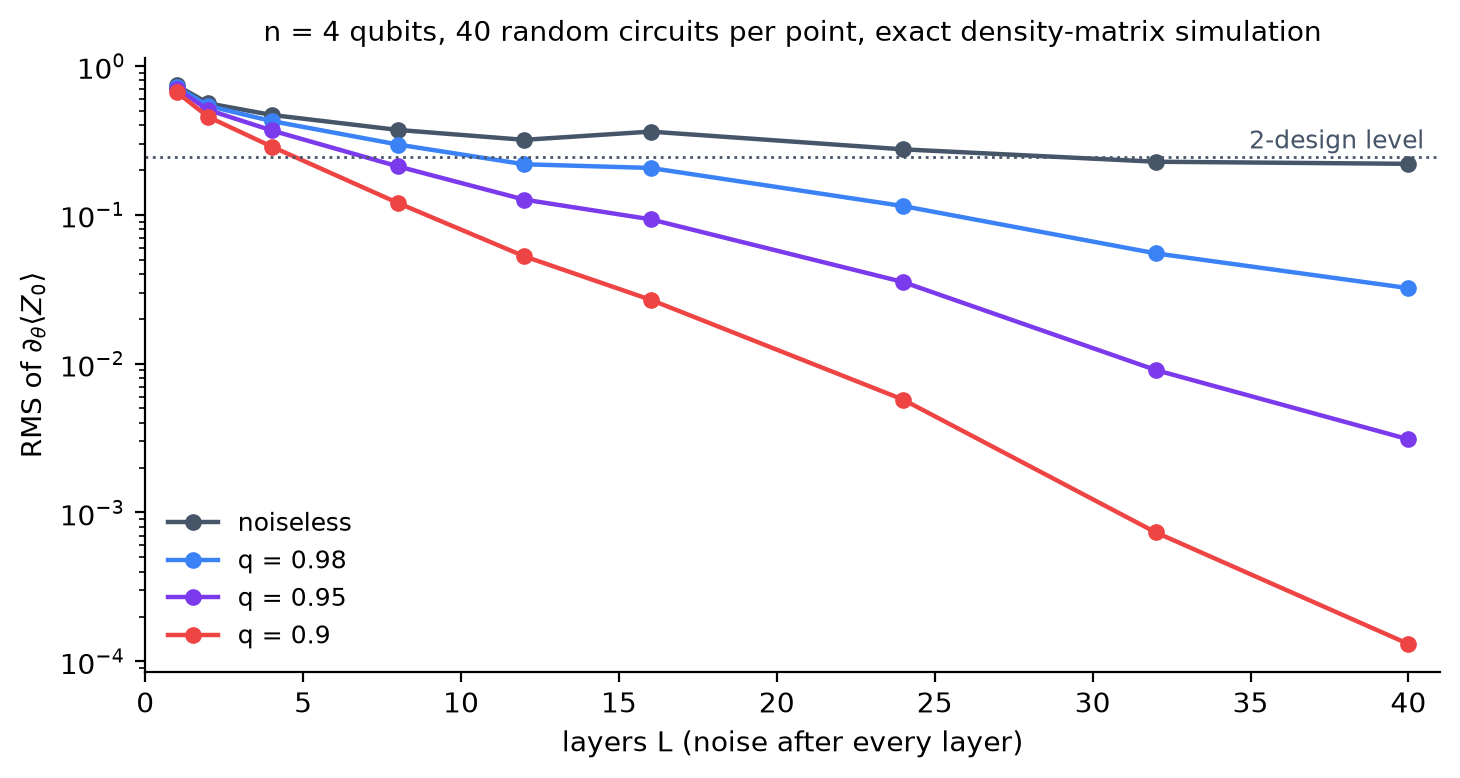

In [5]:
_show_mpl(_lessonfigs.noisy_gradient_decay())

*Our density-matrix simulation of the same circuit family at $n = 4$ with local depolarizing noise $\mathcal{N}(\sigma) = q\sigma$ after every layer. Without noise the RMS gradient settles at the 2-design level $1/\sqrt{17}$; with noise it decays exponentially in depth, faster for smaller $q$.*

## Making and reading a trainability claim

```{mermaid}
graph TD
  A[Fix circuit family and init] --> B[Fix observable and noise model]
  B --> C[Choose sizes n and depths L]
  C --> D[Sample many random inits]
  D --> E[Exact or shot-based gradients]
  E --> F[Variance vs n with error bars]
  E --> G[Shot noise of each estimate]
  F --> H{Exponential trend beyond noise?}
  G --> H
  H -->|yes| I[Report plateau for this ensemble]
  H -->|no| J[Report scaling and its limits]
```

*A protocol for a trainability claim. Every box that is held fixed is part of the claim: a different initialization, observable or noise model is a different ensemble.*

:::{prf:algorithm} Shot budget for a gradient study
:label: alg-l7-04-budget
1. From a pilot or from theory, estimate the gradient variance $v(n)$ at each size.
2. Choose $N \ge c/(2v(n))$ shots per shifted circuit, with $c$ of 4 to 10 if the sign of individual gradients must be read reliably.
3. Total shots for one full gradient of $P$ parameters: $2PN$; for $S$ initializations: $2PNS$.
4. If $2PNS$ grows exponentially in $n$, report that cost; it is the operational meaning of the plateau.
:::

Proposed remedies, such as structured or problem-inspired circuits, local costs, correlated parameters, pre-training and layer-by-layer training, each change the ensemble and so leave Theorem [](#thm-l7-04-bp) behind [@vqa; @noise]. A remedy should be judged on measured gradient scaling at several sizes and on whether the restricted model can still express and generalize to the solution. A circuit restricted enough to avoid scrambling may also be easier to simulate classically, which is a separate question that a trainability claim should not ignore; Cerezo and coauthors collect case-by-case evidence for this link and pose it as an open question, not a theorem [@cerezo2025].

## Worked example

:::{admonition} Budget for a 10-qubit study
:class: tip

A team trains our circuit family on $n = 10$ qubits at depth $L = 256$, where the simulation agrees with the 2-design predictions. Find the typical gradient size for the local and the global observable, the shots per shift needed to match it with one standard deviation of shot noise, the Chebyshev bound on $\Pr[|g| \ge 0.01]$, and the shot count below which no test can reliably detect a gradient of $0.01$.

1. Variances: $\operatorname{Var}_{\mathrm{local}} = 1/(2^{10}+1) = 1/1025 \approx 9.76\times10^{-4}$, so the typical size is $0.0312$; $\operatorname{Var}_{\mathrm{global}} = 1/(2\cdot1024\cdot1025) = 1/2{,}099{,}200 \approx 4.76\times10^{-7}$, typical size $6.9\times10^{-4}$.
2. Shots per shift from $1/\sqrt{2N} = \sqrt{\operatorname{Var}}$: $N = \lceil 1025/2\rceil = 513$ (local) and $N = 1024\cdot 1025 = 1{,}049{,}600$ (global).
3. Chebyshev for the global cost: $\Pr[|g| \ge 0.01] \le 4.76\times10^{-7}/10^{-4} \approx 0.0048$. For the local cost the same bound is $9.76$, which says nothing; local gradients of size $0.01$ are common.
4. Lemma [](#lem-l7-04-lower) with $m = 0$, $\varepsilon = 0.01$: any test using $N \le 1/(4\cdot10^{-4}) = 2500$ shots per shift has error probabilities summing to at least $1/2$.

**Result.** At $n = 10$ the global gradient is so concentrated that fewer than half a percent of random initializations have $|g| \ge 0.01$, and even those need thousands of shots per shift to detect; resolving a typical global gradient takes about a million shots per shift, against about 500 for the local observable.
:::

## Exercises

**1. (Core)** A parameter-shift estimate uses 2000 shots at each shift. Bound its standard deviation. Does this number alone show a barren plateau?

:::{dropdown} Solution
By [](#eq-l7-04-shot), $\operatorname{Var} \le 1/(2\cdot2000) = 1/4000$, so the standard deviation is at most $\sqrt{1/4000} \approx 0.0158$. No: this bounds the estimator's noise at one parameter point. A plateau claim needs the variance of the true gradient across random initializations, at several $n$, under a stated ensemble.
:::

**2. (Core)** Evaluate Proposition [](#prop-l7-04-product) at $n = 10$. By what factor is the global variance smaller than the local one?

:::{dropdown} Solution
$\operatorname{Var}\,\partial_1 C_G = \frac18(3/8)^9 = \frac18\cdot\frac{19683}{134217728} \approx 1.83\times10^{-5}$ and $\operatorname{Var}\,\partial_1 C_L = 1/800 = 1.25\times10^{-3}$. The ratio is about $68$.
:::

**3. (Stretch)** In Proposition [](#prop-l7-04-pred), replace the differentiated $R_Y$ by $R_X$ and then by $R_Z$. Compute both variances in each case, and explain why the lesson fixes the gate to $R_Y$.

:::{dropdown} Solution
For $V = X_0/2$: $A = i[X_0/2, Z_0] = i\cdot\frac12(-2iY_0) = Y_0$, so $\operatorname{Tr}A^2 = 2^n$ and $\operatorname{Var}_{\mathrm{local}} = 1/(2^n+1)$; for the projector $\langle 0|X^2/4|0\rangle - \langle 0|X/2|0\rangle^2 = 1/4$, so again $1/(2\cdot2^n(2^n+1))$. For $V = Z_0/2$: $[Z_0, Z_0] = 0$, and $|u\rangle = |0\rangle|v\rangle$ is an eigenvector of $Z_0$, so both gradients are identically zero. With a random axis, one third of the samples would be exact zeros, producing a spike at 0 that has nothing to do with concentration; fixing $R_Y$ keeps the histogram honest.
:::

**4. (Stretch)** Use Theorem [](#thm-l7-04-bp) to show that for any Pauli-string observable $H$ and Pauli rotation $V = P/2$, $\operatorname{Var}[\partial_\theta E] \le 1/(2^n+1)$, and find when equality holds.

:::{dropdown} Solution
$\operatorname{Tr}H^2 = 2^n$ and $\|V\|_\infty = 1/2$ give $\operatorname{Var} \le 4\cdot\frac14\cdot2^n/(2^n(2^n+1)) = 1/(2^n+1)$. Directly: $\tilde H$ is a unitary conjugate of a Pauli string; if $P$ anticommutes with $\tilde H$ then $[P/2, \tilde H] = P\tilde H$, and $A = iP\tilde H$ satisfies $A^2 = -P\tilde H P\tilde H = \tilde H^2 P^2 = I$, so $\operatorname{Tr}A^2 = 2^n$ and equality holds. That is the case $\tilde H = Z_0$, $P = Y_0$ of Proposition [](#prop-l7-04-pred).
:::

**5. (Challenge)** Under Proposition [](#prop-l7-04-depol) with $p = 0.01$ per layer, how many layers make $(1-p)^L < 2^{-n/2}$ for $n = 50$? Then argue that if $L$ grows linearly in $n$, the shots needed to resolve any gradient component grow exponentially in $n$ at every parameter value, assuming $|\partial E_0| \le 1$.

:::{dropdown} Solution
Solve $L\ln(1/0.99) > 25\ln2$: $L > 17.329/0.010050 = 1724.2$, so $L \ge 1725$. If $L = cn$, then $|\partial E_L| \le (1-p)^{cn}$ everywhere, an exponentially small number $\varepsilon_n$. By Lemma [](#lem-l7-04-lower), detecting a gradient of size $\varepsilon_n$ needs more than $(1 - m^2)/(4\varepsilon_n^2)$ shots per shift (taking $|m| \le 1/2$, say, at least $3/(16\varepsilon_n^2) = \tfrac{3}{16}(1-p)^{-2cn}$), which grows exponentially. Unlike the 2-design case, this holds for every $\theta$, not only for most.
:::

**6. (Challenge)** Prove the first-moment part of Lemma [](#lem-l7-04-moment), $\mathbb{E}|\phi\rangle\langle\phi| = I/d$, using only invariance of the distribution under $U \mapsto WU$, and explain why a 1-design suffices for $\mathbb{E}[\partial_\theta E] = 0$ but not for the variance.

:::{dropdown} Solution
$M = \mathbb{E}|\phi\rangle\langle\phi|$ satisfies $WMW^\dagger = M$ for all unitaries $W$, so $M$ commutes with every unitary and hence with every matrix (unitaries span all matrices). Thus $M = cI$, and $\operatorname{Tr}M = 1$ gives $c = 1/d$. Then $\mathbb{E}\langle\phi|A|\phi\rangle = \operatorname{Tr}(AM) = \operatorname{Tr}A/d = 0$ uses only degree-one averages. The variance involves $\mathbb{E}(|\phi\rangle\langle\phi|)^{\otimes2}$, a degree-two average; a 1-design can have very different second moments, for example the uniform distribution over the $d$ computational basis states, which is a 1-design but gives $\langle\phi|X_0|\phi\rangle = 0$ always.
:::

## Check your understanding

**1. Which evidence supports a barren-plateau claim for a circuit family?**

- **A.** A single gradient estimate with a large error bar
- **B.** One optimizer run that stalled at 8 qubits
- **C.** A loss curve that is flat for 100 iterations
- **D.** Gradient variance over many random initializations decaying exponentially across several $n$, with shot noise reported

:::{dropdown} Show the answer
**D. Gradient variance over many random initializations decaying exponentially across several $n$, with shot noise reported**

A plateau is a statement about the distribution of the true gradient over an ensemble as $n$ grows. A stalled run or a noisy estimate can come from shot noise, a poor learning rate or a local feature of the landscape.
:::

**2. If $U_-$ is a unitary 2-design and $H$ is a Pauli string, what is the largest possible gradient variance for a Pauli rotation?**

- **A.** $1/(2^n(2^n+1))$
- **B.** $1/2$
- **C.** $1/(2^n+1)$
- **D.** $1/n$

:::{dropdown} Show the answer
**C. $1/(2^n+1)$**

Theorem [](#thm-l7-04-bp) gives $\operatorname{Tr}A^2/(d(d+1))$ with $\operatorname{Tr}A^2 \le 4\cdot\frac14\cdot 2^n$, so at most $1/(2^n+1)$, attained when $V$ anticommutes with $\tilde H$.
:::

**3. Why can a global cost have a barren plateau in a circuit with no entangling gates?**

- **A.** Shot noise grows with $n$
- **B.** Its gradient is a product of $n-1$ independent factors, each with mean square $3/8$ below 1
- **C.** Product circuits are unitary 2-designs
- **D.** Global costs are not differentiable

:::{dropdown} Show the answer
**B. Its gradient is a product of $n-1$ independent factors, each with mean square $3/8$ below 1**

For $C_G = 1 - \prod_j\cos^2(\theta_j/2)$, $\partial_1 C_G$ contains $\prod_{j\ge2}\cos^2(\theta_j/2)$, whose mean square is $(3/8)^{n-1}$. No scrambling is involved.
:::

**4. Independent $\pm1$ outcomes have mean $\mu$. What is the variance of the mean of $N$ of them?** *(Review of [L3-07](#lesson-l3-07))*

- **A.** $\mu(1-\mu)/N$
- **B.** $(1-\mu^2)/N$
- **C.** $1/N^2$
- **D.** $(1-\mu)^2$

:::{dropdown} Show the answer
**B. $(1-\mu^2)/N$**

One outcome has $\mathbb{E}z^2 = 1$, so its variance is $1 - \mu^2$; averaging $N$ independent copies divides the variance by $N$.
:::

## Common misconceptions

- **"Barren plateaus mean variational quantum algorithms cannot work."** The theorem is about specified ensembles: circuits whose earlier part scrambles like a 2-design, or noise accumulating with depth. Shallow, structured, or local-cost circuits can have polynomially vanishing gradients; whether they solve useful problems is a separate question.
- **"More shots fix a barren plateau."** More shots reduce estimator noise as $1/\sqrt{N}$. They do not change the true gradient. In a plateau the true gradient is exponentially small, so the shots needed grow exponentially; that cost is the plateau.
- **"Gradient-free optimizers avoid the problem."** Cost differences concentrate too, because they are integrals of the gradient. Along a straight path, Cauchy-Schwarz gives $(E(\theta') - E(\theta))^2 \le \|\theta' - \theta\|^2 \int_0^1 \|\nabla E\|^2 dt$; if every one of $P$ gradient components has second moment at most $v$ at every point, as in Theorem [](#thm-l7-04-bp), then $\mathbb{E}(E(\theta') - E(\theta))^2 \le \|\theta' - \theta\|^2 P v$. Any method must resolve these exponentially small differences with finitely many shots.
- **"Noise-induced plateaus are just barren plateaus with noise added."** They are a different mechanism. The noiseless result is probabilistic over initializations; the noise-induced bound holds at every parameter value and grows with depth, so initialization strategies do not help.

:::{caution} Scope and limits
Theorem [](#thm-l7-04-bp) assumes that the part of the circuit before the parameter is an exact unitary 2-design independent of the rest; real circuits are at best approximate designs, and the depth at which they become one depends on architecture and connectivity. Our simulations are classical Monte Carlo estimates for $n \le 10$ with relative standard errors of about 7 to 10 percent on each variance; they illustrate the theorem and do not establish asymptotic rates. The noise results assume specific channel models (global depolarizing, or local Pauli noise with $q < 1$). Nothing here says that every useful quantum model is untrainable, and nothing here demonstrates a quantum advantage.
:::

:::{seealso} Where this leads
The shot budgets here are the first instance of the resource accounting in [L7-06](#lesson-l7-06), where concentration bounds, queries and gate counts are separated. The identifiability lesson [L7-05](#lesson-l7-05) asks a complementary question: even with perfect gradients, can the trained model's target be pinned down by the data at all?
:::

:::{dropdown} For instructors

**Why this lesson.** Students often meet barren plateaus as a slogan. Deriving the variance from the 2-design moment, checking it against an exact simulation, and converting it into a shot budget turns the slogan into a quantitative, falsifiable statement with explicit assumptions [@plateaus; @noise; @vqa].

**Teaching notes.**

- Start with the two diagnoses from the motivation and ask students to design an experiment that separates them before showing any theorem.
- Spend time on the Schur's lemma step; students who know only the first-moment argument can see why the second moment needs the symmetric subspace [@watrous].
- Use the interactive figure at $L = 1$ and $L = 256$ to show that the same circuit family is or is not on a plateau depending on depth, and that the local and global observables reach it differently.
- Have students compute the shot budget in the worked example before revealing it; the jump from about 500 to about a million shots per shift is the point.

**Assessment.** The stretch exercise on $R_X$ and $R_Z$ checks the commutator calculation behind the predictions; the first challenge checks that students can combine a deterministic noise bound with the shot lower bound; the review check tests the variance of a mean.

**Going further.** Read the variance formula for the case where $U_+$ is the 2-design in [@plateaus] and derive it with the two-design moment of $U^{\otimes 2}XU^{\dagger\otimes2}$. Then read the noise-induced bound in [@noise] and identify which assumption fails for a circuit whose depth grows only logarithmically in $n$.

:::

## References

This lesson draws on [@plateaus; @noise; @vqa; @watrous; @coverthomas; @cerezo2021; @cerezo2025].

**Further reading.**

- [@plateaus]: The original result: gradient mean and variance for random parametrized circuits, and a numerical study of the depth at which the variance saturates.
- [@noise]: Noise-induced barren plateaus for local Pauli noise, with an explicit bound that holds at every parameter value.
- [@vqa]: Review that places barren plateaus among other obstacles and surveys proposed remedies, including cost locality.

**Next:** [L7-05 · Identifiability before quantum causal learning](#lesson-l7-05)
